In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import pandas as pd

In [13]:
def energy_to_freq(E_eV):
    """Convierte energia en frecuencia de eV a GHz."""
    h = 4.135667696e-15  # eV·s
    return E_eV / h/1e9

def freq_to_energy(nu):
    """Convierte frecuencia en energia de GHz a eV."""
    h = 4.135667696e-15  # eV·s
    return nu * h*1e9

/tmp/ipykernel_5656/4040357096.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


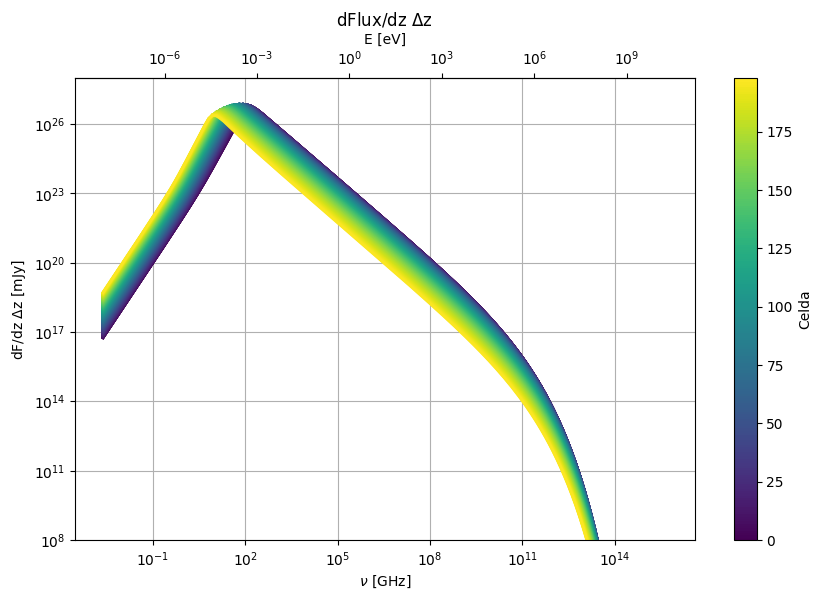

In [ ]:


# Cargar los datos
data = np.loadtxt('./../Code/dFlux_dz.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = y_values.shape[1]

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(energy_to_freq(x), y_values[:, i]*1e26, color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar


ax_top = ax.secondary_xaxis('top', functions=(freq_to_energy,energy_to_freq))
ax.set_xlabel(r'$\nu$ [GHz]')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e8,1e28)
ax.set_xlim(1,1e4)
ax_top.set_xlabel(r'E [eV]')  # Ajustar según los datos
ax.set_ylabel(r'dF/dz $\Delta$z [mJy]')  # Ajustar según los datos
ax.set_title(r'dFlux/dz $\Delta$z')
ax.grid()
plt.show()
# Save the figure
output_path = 'dFdz.png'
fig.savefig(output_path, dpi=300)

In [7]:


# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer columnas
E = data[:, 0]  # Primer columna
N = data[:, 1]  # Segunda columna
Z = data[:, 2]  # Tercera columna

data2 = np.loadtxt('./../Code/quant_FF.dat')
# Encontrar valores únicos de E y Z
r=data2[:, 2]
Deltaz=data2[:, -2]

E_unique = np.unique(E)
Z_unique = np.unique(Z)

# Crear una matriz de N con dimensiones (len(E_unique), len(Z_unique))
N_matrix = np.full((len(E_unique), len(Z_unique)), np.nan)  # Usamos NaN para identificar valores faltantes

# Rellenar la matriz
for e, n, z in zip(E, N, Z):
    i = np.where(E_unique == e)[0][0]
    j = np.where(Z_unique == z)[0][0]
    N_matrix[i, j] = n

N_matrix
# Convert the matrix to a DataFrame
df = pd.DataFrame(N_matrix, index=E_unique, columns=Z_unique)

print(E_unique[1])
Deltaz[:]

1.8612468694701466e-06


array([ 8857.51847769,  8086.19576932,  7526.46785114,  7100.62485958,
        6765.76106095,  6496.02181082,  6274.78989603,  6090.84218578,
        5936.29425364,  5805.42682403,  5693.97942233,  5598.70634318,
        5517.08715031,  5447.13197207,  5387.24699646,  5336.13935756,
        5292.7484814 ,  5256.19561989,  5225.7461463 ,  5200.78097065,
        5180.77458135,  5165.27797358,  5153.90523127,  5146.32287448,
        5142.24132428,  5141.40800588,  5143.60173166,  5148.62809321,
        5156.31565537,  5166.51279285,  5179.08504531,  5193.9128937 ,
        5210.88988105,  5229.9210166 ,  5250.92141432,  5273.81512632,
        5298.53413925,  5325.01750747,  5353.21060173,  5383.06445561,
        5414.53519519,  5447.58353982,  5482.17436379,  5518.27631039,
        5555.86145126,  5594.90498488,  5635.38496913,  5677.28208347,
        5720.57941703,  5765.26227943,  5811.31803151,  5858.73593366,
        5907.5070096 ,  5957.62392396,  6009.08087196,  6061.87347994,
      

/tmp/ipykernel_5656/2349093798.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


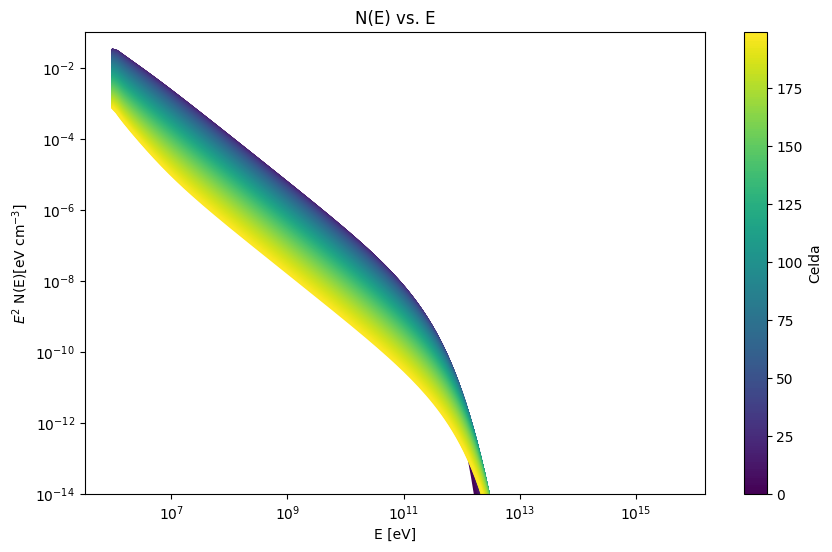

In [ ]:
# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = len(Z_unique)

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    E_eV = E_unique / 1.60218e-12  # 1 eV = 1.60218e-12 erg
    ax.plot(E_eV, E_unique**2*df.iloc[:, i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-14,1e-1)
ax.set_xlim(1,1e4)
ax.set_xlabel(r'E [eV]')  # Ajustar según los datos
ax.set_ylabel(r'$E^2$ N(E)[erg cm$^{-3}$]')  # Ajustar según los datos
ax.set_title(r'N(E) vs. E')

plt.show()
output_path = 'N_E.png'
fig.savefig(output_path, dpi=300)

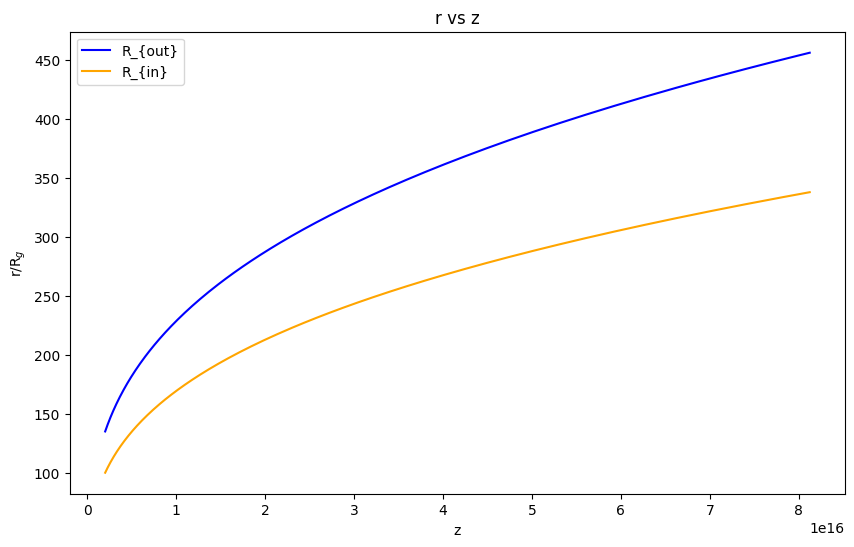

In [9]:
# Extract columns from data2
M_BH = 5.5e7
R_g = 1.477e5*M_BH
Z = data2[:, 0]  # Column 0
r_out = data2[:, 2]  # Column 2
r_in = data2[:, 3]  # Column 3
#print(r_in)
# Plot the data
plt.figure(figsize=(10, 6))
plt.plot(Z, r_out/R_g, label=r'R_{out}', color='blue')
plt.plot(Z, r_in/R_g, label=r'R_{in}', color='orange')
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel('z')
plt.ylabel('r/R$_g$')
plt.title('r vs z')
plt.legend()
fig = plt.gcf()
fig.savefig('R(z).png', dpi=300)

plt.show()


/tmp/ipykernel_5656/742691215.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


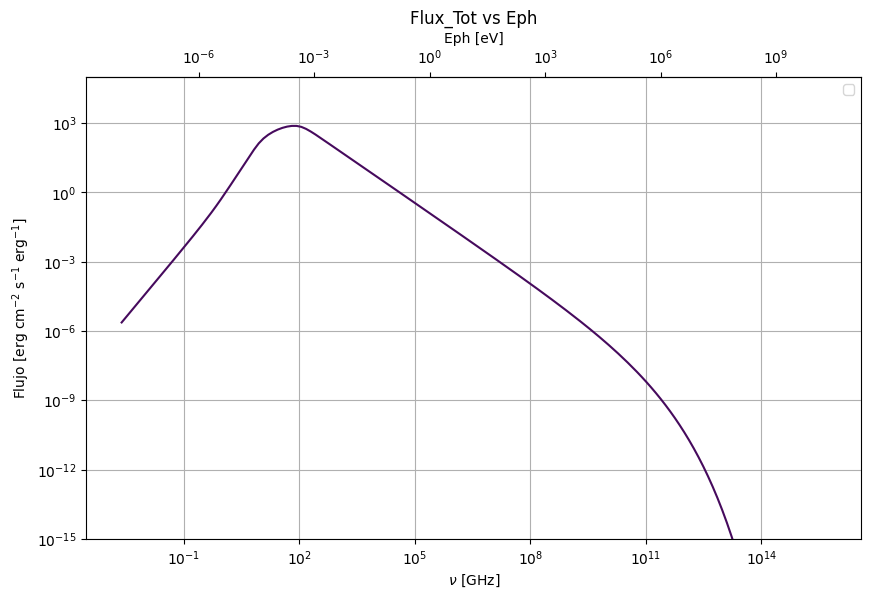

In [ ]:
# Read the data from Flux.dat
df_flux = pd.read_csv('./../Code/Flux.dat', sep='\s+', header=0)
df_flux9 = pd.read_csv('./../Code/Flux.dat', sep='\s+', header=0)
# Plot the first and last column
            
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(energy_to_freq(df_flux9['Eph/eV']), df_flux9['Flujo_Tot'], label=r'', linestyle='-', color=cmap(5))

ax_top = ax.secondary_xaxis('top', functions=(freq_to_energy, energy_to_freq))
ax.set_xlabel(r'$\nu$ [GHz]')
ax.set_xscale('log')
ax.set_yscale('log')
ax_top.set_xlabel('Eph [eV]')
ax.set_ylabel('Flujo [erg cm$^{-2}$ s$^{-1}$ erg$^{-1}$]') #Para pasar a Jy multiplicar por h y multiplicar por 1e-26
ax.set_title('Flux_Tot vs Eph')
ax.set_ylim(1e-15, 1e5)
ax.set_xlim(1,1e4)
ax.legend()
# Save the figure
# output_path = folder_path + 'F.png'
# plt.savefig(output_path, dpi=300)
ax.grid()
fig.savefig('fluxTot.png', dpi=300)

plt.show()


In [8]:
B0 = data2[:, 1]  # Column 2
#B0 #0.3Rg
#B1 #0.1
#B2 #0.3
#B3 #0.5
#B4 #0.7

/tmp/ipykernel_6263/156416342.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


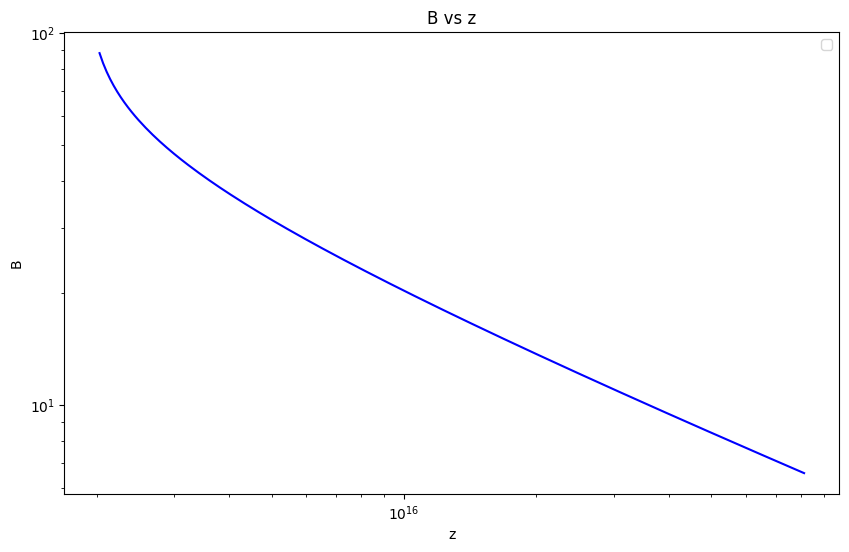

In [9]:
Z = data2[:, 0]  # Column 0
B = data2[:, 1]  # Column 2
plt.figure(figsize=(10, 6))
plt.plot(Z, B, color='blue')
#plt.plot(Z, B1, label=r'R_{in}=0.1R_{out}', color='green')
#plt.plot(Z, B2, label=r'R_{in}=0.3R_{out}', color='orange')
# plt.plot(Z, B3, label=r'R_{in}=0.5R_{out}', color='magenta')
# plt.plot(Z, B4, label=r'R_{in}=0.7R_{out}', color='red')
# plt.plot(Z, B5, label=r'R_{in}=0.9R_{out}', color='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('B')
plt.title('B vs z')
plt.legend()
# Save the figure
output_path = 'B.png'
plt.savefig(output_path, dpi=300)
plt.show()


In [10]:
U_e5=data3[:, 2]
# U_e0
# U_e1
# U_e2
# U_e3
# U_e4

NameError: name 'data3' is not defined

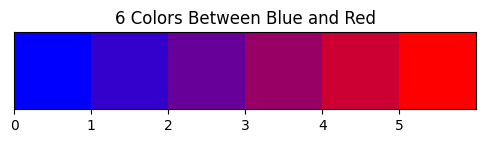

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

import matplotlib.pyplot as plt

# Generate a custom colormap from blue to red
cmap = LinearSegmentedColormap.from_list("blue_red", ["blue", "red"], N=6)

# Get the colors
colors = [cmap(i) for i in range(cmap.N)]

# Display the colors
plt.figure(figsize=(8, 1))
plt.imshow([colors], extent=[0, 6, 0, 1])
plt.gca().set_yticks([])
plt.gca().set_xticks(range(6))
plt.title("6 Colors Between Blue and Red")
plt.show()

200


/tmp/ipykernel_4855/1680239209.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


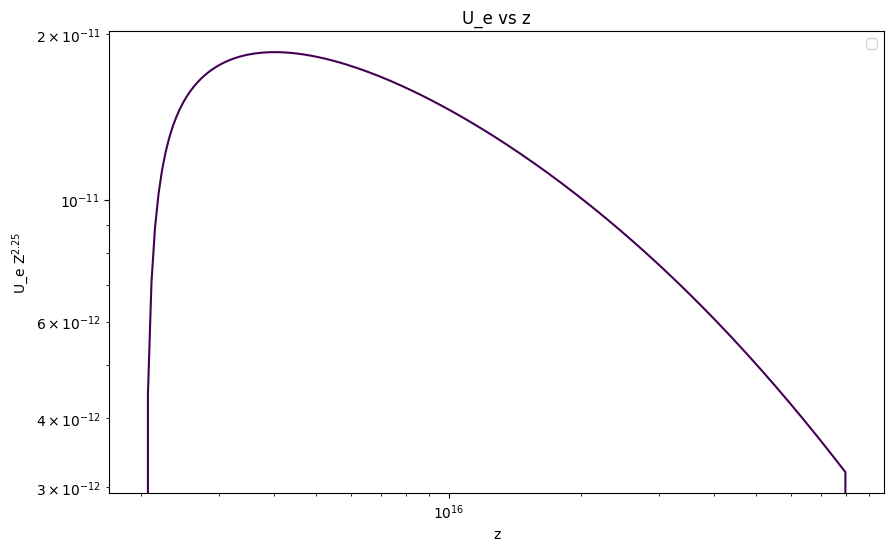

In [ ]:
data3 = np.loadtxt('./../Code/U_e.dat')
# Encontrar valores únicos de E y Z
U_e=data3[:, 2]
Z=data3[:, 1]
print(len(Z))
plt.figure(figsize=(10, 6))
# plt.plot(Z, U_e0*Z**2.25, label=r'$R_{in}=0.3R_g$', color=cmap(5))
# plt.plot(Z, U_e1*Z**2.25, label=r'$R_{in}=0.1R_{out}$', color=cmap(4))
# plt.plot(Z, U_e2*Z**2.25, label=r'$R_{in}=0.3R_{out}$', color=cmap(3))
# plt.plot(Z, U_e3*Z**2.25, label=r'$R_{in}=0.5R_{out}$', color=cmap(2))
# plt.plot(Z, U_e4*Z**2.25, label=r'$R_{in}=0.7R_{out}$', color=cmap(1))
plt.plot(Z, U_e*Z**2.25, color=cmap(0))
plt.xscale('log')
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('U_e Z$^{2.25}$')
plt.title('U_e vs z')
plt.legend()
# # Save the figure
# output_path = folder_path + 'Ue.png'
# plt.savefig(output_path, dpi=300)
plt.show()


In [ ]:
# Read the file using pandas
df_dflux_dz = pd.read_csv('./../Code/dFlux_dz.dat', delim_whitespace=True, header=None)

# Extract the first column as a vector E
E = df_dflux_dz.iloc[:, 0].values

# Extract the other columns as a DataFrame
df_data = df_dflux_dz.iloc[:, 1:]

# Integrate each column over the vector E
integrated_values1 = df_data.apply(lambda col: np.trapz(col, E), axis=0)
# integrated_values0
# integrated_values1
# integrated_values2
# integrated_values3
# integrated_values4

/tmp/ipykernel_4855/3080623445.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_dflux_dz = pd.read_csv('./../Code/dFlux_dz.dat', delim_whitespace=True, header=None)
/tmp/ipykernel_4855/3080623445.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integrated_values1 = df_data.apply(lambda col: np.trapz(col, E), axis=0)


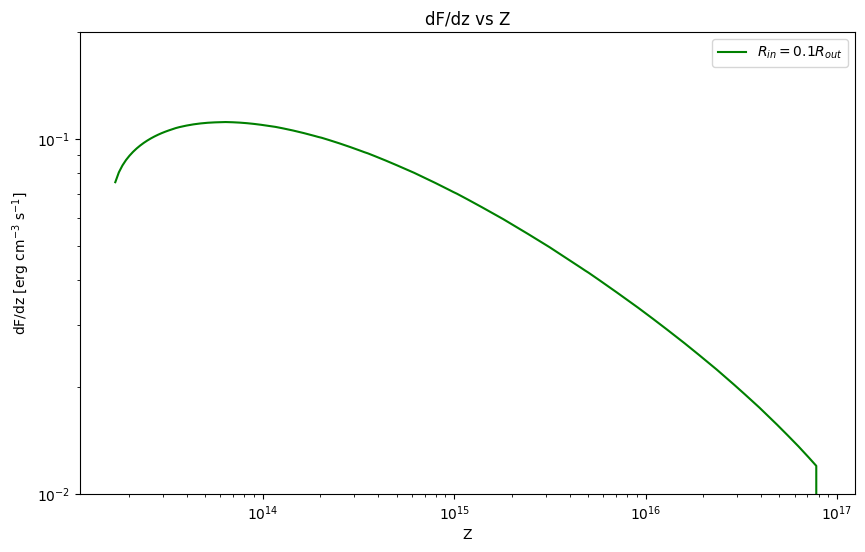

In [ ]:

plt.figure(figsize=(10, 6))
# plt.plot(Z[1:], integrated_values0, label=r'$R_{in}=0.3R_g$', color='blue')
plt.plot(Z[1:], integrated_values1, label=r'$R_{in}=0.1R_{out}$', color='green')
# plt.plot(Z[1:], integrated_values2, label=r'$R_{in}=0.3R_{out}$', color='orange')
# plt.plot(Z[1:], integrated_values3, label=r'$R_{in}=0.5R_{out}$', color='magenta')
# plt.plot(Z[1:], integrated_values4, label=r'$R_{in}=0.7R_{out}$', color='red')
# plt.plot(Z[1:], integrated_values5, label=r'$R_{in}=0.9R_{out}$', color='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Z')
plt.ylabel('dF/dz [erg cm$^{-3}$ s$^{-1}$]')
plt.ylim(1e-2,0.2e0)
plt.title('dF/dz vs Z')
plt.legend()
# Save the figure
output_path = folder_path + 'dF(integrado).png'
plt.savefig(output_path, dpi=300)
plt.show()



El flujo en mJy o Jy con los datos observacionales

El siguiente paso seria graficar los tres, la sed, la imagen y el grafico a la vez y empezar a escribir pls